# 02 — Literature baseline: Gessert et al. (2018), reproduced

> N. Gessert et al., *Skin Lesion Diagnosis using Ensembles, Unscaled Multi-Crop Evaluation and Loss Weighting*,
> ISIC 2018 challenge report, [arXiv:1808.01694](https://arxiv.org/abs/1808.01694). Code: [ngessert/isic2018](https://github.com/ngessert/isic2018).

**Why this paper.** 2nd place in ISIC 2018 Task 3 (official test balanced accuracy **0.856**) and the best entry using only
public data. It reports *single-model* results under lesion-grouped 5-fold CV with every hyperparameter given, so a single
model can be reproduced and compared fairly.

| | Paper | Our reproduction (`literature_baseline_gessert2018.py`) |
|---|---|---|
| Backbone | DenseNet-121, ImageNet-pretrained, full fine-tune | same (`densenet121.tv_in1k`) |
| Input | full 600×450 image, **unscaled** random 224 crops, H/V flips, brightness 32/255 + saturation 0.5 jitter | same |
| Loss | cross-entropy weighted by wᵢ = N/nᵢ | same |
| Optimiser | Adam, lr 5e-4, batch 40, ×0.2 at epochs 50/75/100, 125 epochs | same |
| Selection / eval | best WACC every 5 epochs (16 crops); final 36 grid crops averaged | same |
| Folds | authors' lesion-grouped split | our lesion-grouped split (shared by all experiments) |
| Normalisation, precision | mean subtraction, fp32 | ImageNet mean/std, bf16 |

**Reproduce (one 4-GPU node, ~75 min for all folds):**
`salloc -A m4012 -C gpu -q interactive -N 1 -G 4 -t 03:00:00 srun -n 1 -c 128 -G 4 bash slurm/run_all_node.sh`

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Results below are loaded from results/. Set RUN_TRAINING = True (on a GPU node) to re-create
# one fold of this version first; the full 5-fold runs use the slurm/ drivers listed above.
RUN_TRAINING = False

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

In [2]:
if RUN_TRAINING:   # one fold, ~37 min on an A100
    run("python literature_baseline_gessert2018.py --fold 0")
    run("python literature_baseline_gessert2018.py --summarize")

## 1. Reproduction check: 5-fold CV against the paper (Table II)

In [3]:
RUN = "gessert2018_densenet121"
cv = A.per_fold(RUN, "cv_val")
display(cv.round(4))
print(f"CV balanced accuracy: ours {cv.bal_acc.mean():.3f} ± {cv.bal_acc.std(ddof=0):.3f}   paper 0.795")
print(f"CV accuracy:          ours {cv.acc.mean():.3f}             paper 0.823")
print(f"CV mean AUC:          ours {cv.auc.mean():.3f}             paper 0.967")

,bal_acc,acc,f1,auc,mel_sens,mel_spec,best_epoch
fold,,,,,,,
0,0.7795,0.8503,0.7468,0.9670,0.6457,0.9483,95
1,0.7923,0.8432,0.7413,0.9715,0.7477,0.9337,85
2,0.8215,0.8497,0.7546,0.9718,0.6937,0.9472,60
3,0.8045,0.8278,0.7243,0.9635,0.7220,0.9191,70
4,0.8280,0.8632,0.7918,0.9704,0.7713,0.9393,90


CV balanced accuracy: ours 0.805 ± 0.018   paper 0.795
CV accuracy:          ours 0.847             paper 0.823
CV mean AUC:          ours 0.969             paper 0.967


In [4]:
# The paper notes a large gap between the best-WACC checkpoint and the last one. How large is it here?
gap = pd.DataFrame({k: {"best": A.fold_metrics(RUN, k)["best_checkpoint"]["cv_val"]["balanced_acc"],
                        "last": A.fold_metrics(RUN, k)["last_checkpoint"]["cv_val"]["balanced_acc"]} for k in A.folds(RUN)}).T
gap["best - last"] = gap.best - gap["last"]
gap.round(4)

,best,last,best - last
0,0.7795,0.7808,-0.0013
1,0.7923,0.7966,-0.0043
2,0.8215,0.8164,0.0050
3,0.8045,0.7804,0.0241
4,0.8280,0.8259,0.0021


## 2. Official test set, against our plain ResNet-50 baseline

In [5]:
runs, names = ["resnet50_ce", RUN], ["ResNet-50 plain CE (baseline)", "Gessert DenseNet-121 (reproduction)"]
A.summary(runs, names=names)

,bal_acc,acc,f1,auc,mel_sens,mel_spec,ensemble_bal_acc,n_folds
ResNet-50 plain CE (baseline),0.724 ± 0.012,0.834 ± 0.012,0.740 ± 0.015,0.966 ± 0.002,0.599 ± 0.032,0.953 ± 0.011,0.766,5
Gessert DenseNet-121 (reproduction),0.770 ± 0.012,0.818 ± 0.009,0.743 ± 0.013,0.965 ± 0.002,0.749 ± 0.014,0.916 ± 0.008,0.787,5


In [6]:
# Paired over the same 5 folds (same split, same seed): reproduction minus baseline
A.paired_table([RUN], "resnet50_ce", names=["Gessert - baseline"])

,cv_bal_acc,cv_mel_sens,cv_auc,test_bal_acc,test_mel_sens,test_auc
Gessert - baseline,+0.046 ± 0.013 (5/5),+0.100 ± 0.064 (5/5),+0.000 ± 0.003 (1/5),+0.047 ± 0.019 (5/5),+0.150 ± 0.031 (5/5),-0.001 ± 0.004 (2/5)


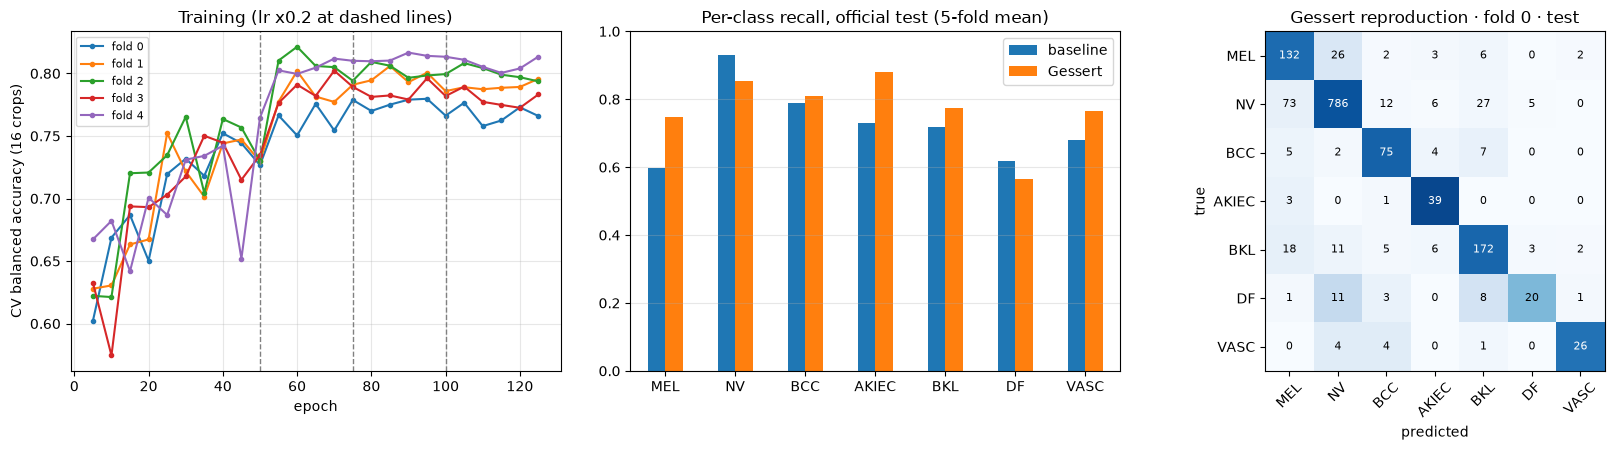

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
h = A.history(RUN).dropna(subset=["val_balanced_acc"])
for k, g in h.groupby("fold"):
    axes[0].plot(g.epoch, g.val_balanced_acc, marker="o", ms=3, label=f"fold {k}")
for e in (50, 75, 100):
    axes[0].axvline(e, ls="--", c="grey", lw=1)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("CV balanced accuracy (16 crops)"); axes[0].set_title("Training (lr x0.2 at dashed lines)")
axes[0].grid(alpha=.3); axes[0].legend(fontsize=8)
rec = pd.DataFrame({n: A.per_class_recall(r) for r, n in zip(runs, ["baseline", "Gessert"])})
rec.plot.bar(ax=axes[1], rot=0); axes[1].set_title("Per-class recall, official test (5-fold mean)"); axes[1].set_ylim(0, 1); axes[1].grid(axis="y", alpha=.3)
A.plot_confusion(axes[2], RUN, 0, "Gessert reproduction · fold 0 · test")
plt.tight_layout()

## Takeaways
* **The reproduction works:** 5-fold CV balanced accuracy 0.805 ± 0.018 vs 0.795 in the paper.
* On the official test set a single model scores 0.770 ± 0.012; averaging the 5 fold models gives 0.787 (the paper's
  54-model ensemble + SVM meta-learner reached 0.856).
* Compared with the plain ResNet-50 baseline it trades accuracy for minority-class recall: +0.047 balanced accuracy and
  +0.15 melanoma sensitivity (5/5 folds), mostly from its class-weighted loss (see notebook 03).
* The best-vs-last checkpoint gap is small here (≤ 0.025), smaller than the paper suggests.
* There is a CV → test drop (0.805 → 0.770); the test set contains images from sources absent from HAM10000.